<a href="https://colab.research.google.com/github/maxiangt/MSSP607/blob/main/Modules/Week_10/Week_7_Internet_Sales_Improved.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Yearly Internet Sales Analysis (Improved Version)

This notebook loads the Internet Sales data, totals `SalesAmount` by year, and draws a bar chart.

**What improved compared with the original notebook**

| Area | Original | Improved |
|---|---|---|
| Portability | `google.colab` upload in the first cell, so it only ran in Colab | Reads the CSV from GitHub; falls back to a local file, then to a Colab upload |
| Efficiency and privacy | Loaded all 60 columns, including customer names, emails and addresses | Loads only the 2 columns needed (`OrderDate`, `SalesAmount`) |
| Error handling | Crashed on missing columns or bad dates | Checks columns, converts bad dates/amounts safely and reports dropped rows |
| Structure | One long script | Small functions with docstrings: load, clean, summarize, plot |
| Analysis | Only yearly totals | Adds months of data per year, partial-year flag and year-over-year change |
| Chart | No value labels; automatic download only | Labels, legend, partial years marked; saved as PDF and PNG |

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch

%matplotlib inline

IN_COLAB = "google.colab" in sys.modules
pd.options.display.float_format = "{:,.2f}".format
print(f"pandas {pd.__version__} | Running in Colab: {IN_COLAB}")

pandas 2.2.3 | Running in Colab: True


## 2. Load the data

`load_sales_data()` tries these sources in order and stops at the first one that works:

1. The file on GitHub (course repository)
2. The earlier GitHub copy of the same file
3. A local copy next to the notebook (or in Colab's `/content`)
4. In Colab only: a file-upload prompt

Only the two columns needed are read, which is faster and avoids loading customers' personal information.

In [2]:
DATA_FILE = "InternetSales.csv"
DATA_URLS = [
    "https://raw.githubusercontent.com/maxiangt/MSSP607/refs/heads/main/Modules/Week_7/" + DATA_FILE,
    "https://raw.githubusercontent.com/maxiangt/MSSP6070/main/Assignments/" + DATA_FILE,
]
REQUIRED_COLUMNS = ["OrderDate", "SalesAmount"]


def read_sales(source):
    """Read only the required columns from a CSV path or URL.
    Raises ValueError if a required column is missing."""
    return pd.read_csv(source, usecols=REQUIRED_COLUMNS, encoding="latin-1")


def find_local_file(filename):
    """Return the Path of `filename` in the current folder or /content, otherwise None."""
    for folder in (Path.cwd(), Path("/content")):
        if (folder / filename).exists():
            return folder / filename
    return None


def load_sales_data():
    """Return (DataFrame, description of the source). Raises FileNotFoundError if nothing works."""
    for url in DATA_URLS:
        try:
            return read_sales(url), url
        except Exception as error:
            print(f"Could not read {url}\n  -> {error}")

    local_path = find_local_file(DATA_FILE)
    if local_path is not None:
        return read_sales(local_path), f"local file: {local_path}"

    if IN_COLAB:
        from google.colab import files
        print("Please upload InternetSales.csv:")
        uploaded = files.upload()
        if uploaded:
            name = next(iter(uploaded))
            return read_sales(name), f"uploaded file: {name}"

    raise FileNotFoundError(
        f"Could not find {DATA_FILE}. Put it next to this notebook or upload it to the repository."
    )


raw_sales, data_source = load_sales_data()
print(f"Loaded {len(raw_sales):,} rows from {data_source}")
raw_sales.head()

Loaded 60,398 rows from https://raw.githubusercontent.com/maxiangt/MSSP607/refs/heads/main/Modules/Week_7/InternetSales.csv


,SalesAmount,OrderDate
0,"3,399.99",1/19/2011
1,"2,319.99",1/18/2013
2,21.98,1/18/2013
3,"2,384.07",5/3/2013
4,28.99,5/3/2013


## 3. Clean the data

Dates and amounts are converted safely: values that cannot be converted become missing, and those rows are removed and counted so nothing disappears silently.

In [3]:
def clean_sales(df):
    """Convert types, drop unusable rows (and report how many), and add a Year column."""
    df = df.copy()
    df["OrderDate"] = pd.to_datetime(df["OrderDate"], errors="coerce")
    df["SalesAmount"] = pd.to_numeric(df["SalesAmount"], errors="coerce")

    unusable = df[REQUIRED_COLUMNS].isna().any(axis=1).sum()
    if unusable:
        print(f"Dropped {unusable:,} rows with a missing or invalid date/amount.")
    df = df.dropna(subset=REQUIRED_COLUMNS)

    df["Year"] = df["OrderDate"].dt.year
    return df


sales = clean_sales(raw_sales)
print(f"{len(sales):,} rows kept | orders from {sales['OrderDate'].min():%Y-%m-%d} "
      f"to {sales['OrderDate'].max():%Y-%m-%d}")

60,398 rows kept | orders from 2010-12-29 to 2014-01-28


## 4. Yearly sales summary

Besides the yearly total (the original result), the table shows how many months have data in each year. A year with fewer than 12 months is flagged as **partial**, because comparing it with a full year would be misleading.

In [4]:
def summarize_yearly_sales(df):
    """Total sales, order lines, months with data, partial-year flag and year-over-year change."""
    grouped = df.groupby("Year")
    summary = pd.DataFrame({
        "TotalSales": grouped["SalesAmount"].sum(),
        "OrderLines": grouped.size(),
        "MonthsWithData": grouped["OrderDate"].apply(lambda s: s.dt.month.nunique()),
    })
    summary["PartialYear"] = summary["MonthsWithData"] < 12

    # Year-over-year change only when both years are complete.
    complete = ~summary["PartialYear"]
    both_complete = complete & complete.shift(fill_value=False)
    summary["YoYChangePct"] = (summary["TotalSales"].pct_change() * 100).where(both_complete)
    return summary


yearly_summary = summarize_yearly_sales(sales)
yearly_summary

,TotalSales,OrderLines,MonthsWithData,PartialYear,YoYChangePct
Year,,,,,
2010,"43,421.04",14,1,True,NaN
2011,"7,075,525.93",2216,12,False,NaN
2012,"5,842,485.20",3397,12,False,-17.43
2013,"16,351,550.34",52801,12,False,179.87
2014,"45,694.72",1970,1,True,NaN


## 5. Bar chart

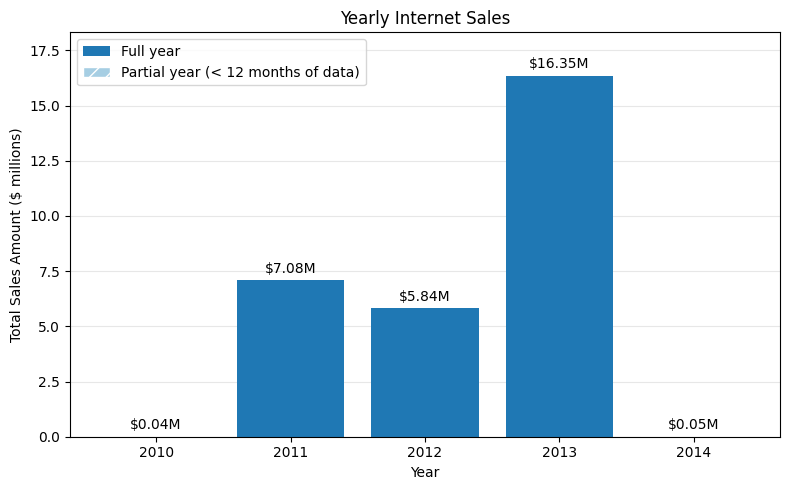

In [5]:
def plot_yearly_sales(summary, save_stem="yearly_sales"):
    """Bar chart of yearly sales in $ millions; partial years are lighter and hatched.
    Saves <save_stem>.pdf and <save_stem>.png and returns the figure."""
    fig, ax = plt.subplots(figsize=(8, 5))
    values = summary["TotalSales"] / 1e6

    bars = ax.bar(summary.index.astype(str), values, color="#1f78b4")
    for bar, is_partial in zip(bars, summary["PartialYear"]):
        if is_partial:
            bar.set_facecolor("#a6cee3")
            bar.set_hatch("//")
            bar.set_edgecolor("white")

    ax.bar_label(bars, labels=[f"${v:,.2f}M" for v in values], padding=3)
    ax.margins(y=0.12)
    ax.set_title("Yearly Internet Sales")
    ax.set_xlabel("Year")
    ax.set_ylabel("Total Sales Amount ($ millions)")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    if summary["PartialYear"].any():
        ax.legend(handles=[Patch(facecolor="#1f78b4", label="Full year"),
                           Patch(facecolor="#a6cee3", hatch="//", edgecolor="white",
                                 label="Partial year (< 12 months of data)")])

    fig.tight_layout()
    fig.savefig(f"{save_stem}.pdf")
    fig.savefig(f"{save_stem}.png", dpi=150)
    return fig


fig = plot_yearly_sales(yearly_summary)
plt.show()

In [6]:
# Download the PDF (only works in Colab; set to False to skip).
DOWNLOAD_PDF = True

if IN_COLAB and DOWNLOAD_PDF:
    from google.colab import files
    files.download("yearly_sales.pdf")
else:
    print("Chart saved as yearly_sales.pdf and yearly_sales.png in the current folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Summary

- Sales are highest in 2013 and lowest among full years in 2012; 2010 and 2014 contain only about one month of data each, so they should not be compared with full years.
- The code now runs in Colab and locally, loads only the columns it needs, and reports problems instead of crashing.